<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/01_ward.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Результаты:
   space  method  k  actual_clusters  silhouette  davies_bouldin  calinski_harabasz  smallest_cluster  largest_cluster  converged
absolute Average  2                2       0.652           0.251             13.917                 1             1024       True
absolute Average  3                3       0.600           0.352             17.670                 1             1022       True
absolute Average  4                4       0.346           0.413             12.994                 1             1021       True
absolute  KMeans  2                2       0.295           1.262            493.637               435              590       True
absolute Average  5                5       0.262           0.774             22.282                 1              996       True
absolute    Ward  2                2       0.261           1.245            41

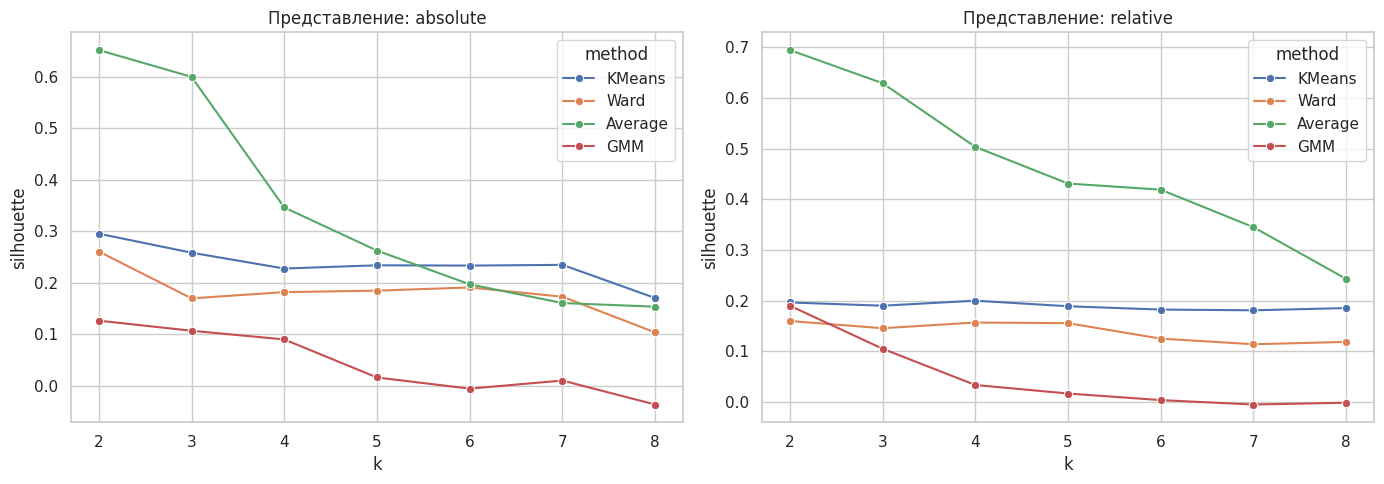


Лучший кандидат в absolute: Average, k=2, silhouette=0.652

Лучший кандидат в relative: Average, k=2, silhouette=0.694

Анализируем: KMeans, k=3
Размеры кластеров:
cluster
0    329
1    401
2    295
Name: count, dtype: int64

Средние исходные характеристики:
           hp  attack  defense  sp_attack  sp_defense  speed
cluster                                                     
0        76.9    93.9     85.8       54.1        63.6   54.4
1        65.5    77.7     59.1       75.1        61.2   86.2
2        69.0    59.0     76.0       81.1        89.8   55.6

Сумма статов по кластерам:
         count   mean    std    min    max
cluster                                   
0          329  428.6  108.0  195.0  680.0
1          401  424.9  117.7  175.0  720.0
2          295  430.5  111.4  180.0  680.0

Средние доли характеристик, %:
           hp  attack  defense  sp_attack  sp_defense  speed
cluster                                                     
0        18.1    21.8     20.1       1

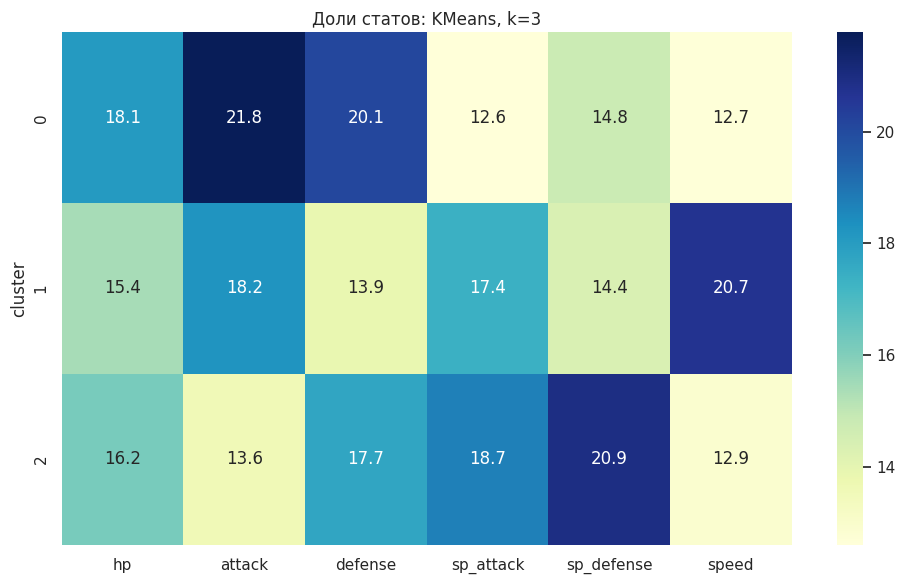


Представители кластеров:

Кластер 0:
       name   type_1  cluster  hp  attack  defense  sp_attack  sp_defense  speed
Iron-Thorns     Rock        0 100     134      110         70          84     72
   Torterra    Grass        0  95     109      105         75          85     56
   Totodile    Water        0  50      65       64         44          48     43
    Pancham Fighting        0  67      82       62         46          48     43
   Maschiff     Dark        0  60      78       60         40          51     51

Кластер 1:
    name type_1  cluster  hp  attack  defense  sp_attack  sp_defense  speed
  Swanna  Water        1  75      87       63         87          63     98
Chimchar   Fire        1  44      58       44         58          44     61
 Pansear   Fire        1  50      53       48         53          48     64
 Panpour  Water        1  50      53       48         53          48     64
 Pansage  Grass        1  50      53       48         53          48     64

Кластер

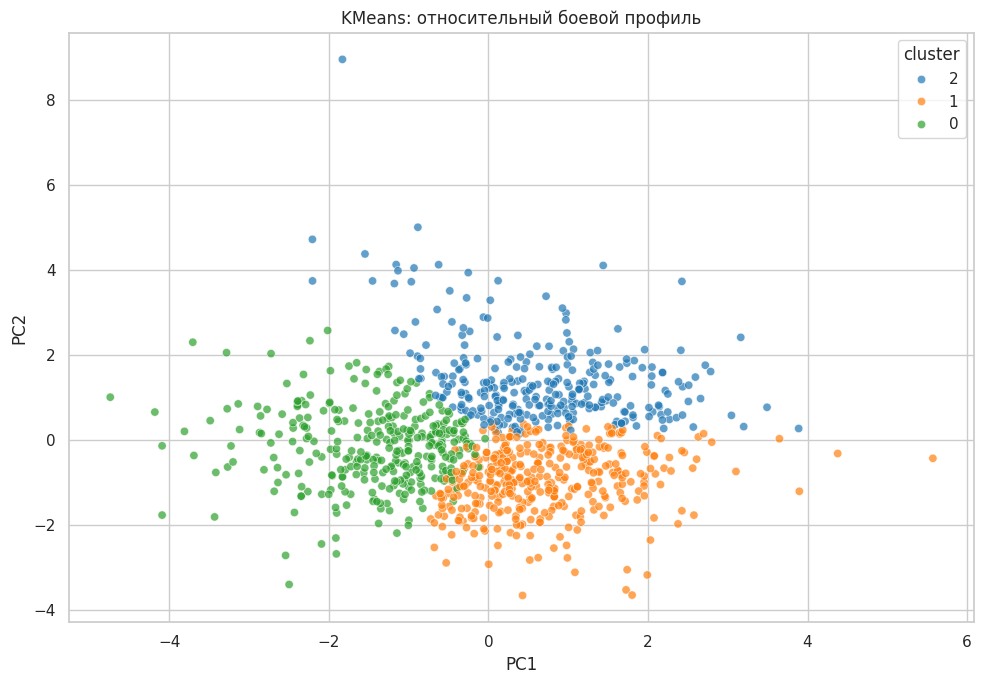

Доля дисперсии двух PCA-компонент: 0.576


In [ ]:
# 1. Библиотеки и загрузка
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.decomposition import PCA

from google.colab import drive

sns.set_theme(style="whitegrid")

drive.mount("/content/drive")

PATH = "/content/drive/MyDrive/datasets/pokemon_complete.csv"
STATS = ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed"]

raw = pd.read_csv(PATH, encoding="utf-8-sig")

# Для данного файла: основные записи, без альтернативных форм.
df = raw.loc[raw["pokedex_number"].between(1, 1025)].copy()
SEED = 55

STATS = [
    "hp", "attack", "defense",
    "sp_attack", "sp_defense", "speed",
]

sns.set_theme(style="whitegrid")


# 1. Проверка и подготовка
df = df.reset_index(drop=True).copy()

stats = df[STATS].apply(pd.to_numeric, errors="raise")

if stats.isna().any().any():
    raise ValueError("В признаках появились пропуски")

if np.isinf(stats.to_numpy(dtype=float)).any():
    raise ValueError("В характеристиках есть бесконечные значения")

if (stats < 0).any().any():
    raise ValueError("Обнаружены отрицательные характеристики")

#print("Пропуски:")
#print(stats.isna().sum())

filled = stats.to_numpy(dtype=float)

totals = filled.sum(axis=1, keepdims=True)

if (totals <= 0).any():
    raise ValueError("Сумма характеристик должна быть положительной")


# 2. Два представления данных
# Абсолютные статы: сохраняют общий уровень силы.
X_absolute = StandardScaler().fit_transform(filled)

# Относительные статы: описывают распределение характеристик.
# Например, attack / сумма всех шести статов.
relative = filled / totals
X_relative = StandardScaler().fit_transform(relative)

spaces = {
    "absolute": X_absolute,
    "relative": X_relative,
}


# 3. Создание моделей
def build_models(k):
    return {
        "KMeans": KMeans(
            n_clusters=k,
            n_init=20,
            random_state=SEED,
        ),
        "Ward": AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean",
        ),
        "Average": AgglomerativeClustering(
            n_clusters=k,
            linkage="average",
            metric="euclidean",
        ),
        "GMM": GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=5,
            reg_covar=1e-4,
            random_state=SEED,
        ),
    }


# 4. Сравнение методов и числа кластеров
rows = []
assignments = {}

for space_name, X in spaces.items():
    for k in range(2, min(8, len(df) - 1) + 1):
        for method_name, model in build_models(k).items():
            labels = model.fit_predict(X)
            sizes = pd.Series(labels).value_counts()

            # Для расчёта метрик нужны хотя бы два кластера.
            if not 2 <= len(sizes) < len(X):
                continue

            key = (space_name, method_name, k)
            assignments[key] = labels

            rows.append({
                "space": space_name,
                "method": method_name,
                "k": k,
                "actual_clusters": len(sizes),
                "silhouette": silhouette_score(X, labels),
                "davies_bouldin": davies_bouldin_score(X, labels),
                "calinski_harabasz": calinski_harabasz_score(X, labels),
                "smallest_cluster": sizes.min(),
                "largest_cluster": sizes.max(),
                "converged": (
                    bool(model.converged_)
                    if method_name == "GMM"
                    else True
                ),
            })

results = pd.DataFrame(rows)

if results.empty:
    raise ValueError("Не удалось получить варианты кластеризации")

print("\nРезультаты:")
print(
    results.sort_values(
        ["space", "silhouette"],
        ascending=[True, False],
    ).round(3).to_string(index=False)
)

results.to_csv("clustering_comparison.csv", index=False)


# 5. Графики silhouette
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, space_name in zip(axes, spaces):
    sns.lineplot(
        data=results.loc[results["space"] == space_name],
        x="k",
        y="silhouette",
        hue="method",
        marker="o",
        ax=ax,
    )
    ax.set_title(f"Представление: {space_name}")
    ax.set_xticks(range(2, 9))

plt.tight_layout()
plt.show()


# 6. Лучший численный кандидат в каждом пространстве
eligible = results.loc[results["converged"]].copy()

for space_name in spaces:
    candidates = eligible.loc[eligible["space"] == space_name]

    if candidates.empty:
        continue

    best = candidates.sort_values(
        "silhouette", ascending=False
    ).iloc[0]

    print(
        f"\nЛучший кандидат в {space_name}: "
        f"{best['method']}, k={int(best['k'])}, "
        f"silhouette={best['silhouette']:.3f}"
    )


# 7. Выбор для анализа боевого стиля
# Выбираем внутри relative, поскольку нас интересует стиль, а не сила.
candidates = eligible.loc[eligible["space"] == "relative"]

if candidates.empty:
    raise ValueError("Нет допустимых кандидатов для relative")

best = candidates.sort_values(
    "silhouette", ascending=False
).iloc[0]

#chosen_method = best["method"]
#chosen_k = int(best["k"])

# После просмотра таблиц можно явно выбрать другой вариант:
# автовыбор Average linkage с k= 2 показывает фактически единую группу покемонов, что означает, что разбить их на группы по сугубо боевым статам нельзя.
# пробуем ->
chosen_method = "KMeans"
chosen_k = 3

labels = assignments[("relative", chosen_method, chosen_k)]
df["cluster"] = labels

print(f"\nАнализируем: {chosen_method}, k={chosen_k}")
print("Размеры кластеров:")
print(df["cluster"].value_counts().sort_index())


# 8. Профили групп в исходных единицах
raw_profiles = (
    pd.DataFrame(filled, columns=STATS)
    .assign(cluster=labels)
    .groupby("cluster")[STATS]
    .mean()
)

print("\nСредние исходные характеристики:")
print(raw_profiles.round(1).to_string())

# Проверяем, осталась ли связь кластеров с общей силой.
strength = pd.DataFrame({
    "cluster": labels,
    "total": totals.ravel(),
})

print("\nСумма статов по кластерам:")
print(
    strength.groupby("cluster")["total"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(1)
    .to_string()
)


# 9. Относительные профили — основа интерпретации
relative_profiles = (
    pd.DataFrame(relative * 100, columns=STATS)
    .assign(cluster=labels)
    .groupby("cluster")[STATS]
    .mean()
)

print("\nСредние доли характеристик, %:")
print(relative_profiles.round(1).to_string())

plt.figure(figsize=(10, 6))
sns.heatmap(
    relative_profiles,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
)
plt.title(f"Доли статов: {chosen_method}, k={chosen_k}")
plt.tight_layout()
plt.show()


# 10. Представители, близкие к среднему профилю кластера
X = X_relative

print("\nПредставители кластеров:")

for cluster_id in sorted(np.unique(labels)):
    indices = np.flatnonzero(labels == cluster_id)
    center = X[indices].mean(axis=0)

    distances = np.linalg.norm(X[indices] - center, axis=1)
    nearest = indices[np.argsort(distances)[:5]]

    print(f"\nКластер {cluster_id}:")
    print(
        df.iloc[nearest][
            ["name", "type_1", "cluster", *STATS]
        ].to_string(index=False)
    )


# 11. PCA для визуализации, не для построения кластеров
pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_relative)

plot_data = pd.DataFrame({
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1],
    "cluster": labels.astype(str),
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.7,
)
plt.title(f"{chosen_method}: относительный боевой профиль")
plt.tight_layout()
plt.show()

print(
    "Доля дисперсии двух PCA-компонент:",
    round(pca.explained_variance_ratio_.sum(), 3),
)


# 12. Сохранение
df.to_csv(
    "selected_clusters.csv",
    index=False,
    encoding="utf-8-sig",
)

relative_profiles.to_csv(
    "relative_cluster_profiles.csv",
    encoding="utf-8-sig",
)

В результате кластеризации относительных боевых характеристик методом KMeans с тремя кластерами выделены физический, скоростной со смешанной атакой и специальный профили. Средние суммы характеристик групп практически одинаковы — от 424,9 до 430,5, поэтому разбиение преимущественно отражает распределение статов, а не общий уровень силы.

Три кластера рассматриваются как компромисс между компактностью представления и интерпретируемостью. Внутренние метрики не указывают на однозначное превосходство этого варианта над двумя или четырьмя кластерами. Двумерная PCA-проекция сохраняет 57,6% дисперсии и используется только для визуализации. Умеренные значения silhouette свидетельствуют о перекрытии профилей; устойчивость разбиения требует дополнительной проверки.

Интерпретация кластеров

0	329	Высокие доли физической атаки — 21,8% и защиты — 20,1%; небольшие доли специальной атаки и скорости	**Физический, сравнительно медленный профиль**

1	401	Наибольшая доля скорости — 20,7%; близкие доли физической и специальной атаки; меньшие доли защиты	**Скоростной профиль со смешанной атакой**

2	295	Высокие доли специальной защиты — 20,9% и специальной атаки — 18,7%; небольшие доли физической атаки и скорости	**Специальный, сравнительно медленный профиль**

k	Silhouette ↑	Davies–Bouldin ↓	Calinski–Harabasz ↑	Интерпретация
* 2	0,196	1,828	239,844	Физический и специальный профили
* 3	0,190	1,528	234,807	Дополнительно выделен скоростной профиль
* 4	0,200	1,412	216,253	Более подробная специализация, включая высокий HP


k=3 — разумный компромисс между простотой и содержательностью:

* все группы достаточно крупные;
* выделяется самостоятельный скоростной профиль;
* Davies–Bouldin лучше, чем при k=2;
* Calinski–Harabasz лишь немного ниже, чем при k=2;

Четыре группы дают лучшую геометрическую разделённость по двум метрикам, но требуют более подробной интерпретации.

При этом численного преимущества по всем метрикам у k=3 нет, а silhouette около 0,19 указывает на заметное перекрытие групп.

Их следует воспринимать как полезное обобщение непрерывного разнообразия профилей, а не как строгую игровую классификацию.

Average linkage показал самые высокие silhouette и низкие Davies–Bouldin. Но при k=2 он выделил один объект в отдельный кластер, а остальные 1024 — в другой.

Такое разбиение может быть полезным для поиска необычного объекта, но не отвечает задаче содержательной сегментации большинства покемонов. Поэтому Average не выбран, несмотря на высокий silhouette.